In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import random

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import h5py
path = "/content/drive/My Drive/Datasets/TrainAndTestDataset.mat"

file =h5py.File(path,'r')

In [ ]:
file.keys()

<KeysViewHDF5 ['DistAll', 'LineAll', 'RfAll', 'Xall', 'Yall']>

In [ ]:
import numpy as np
X = np.array(file['Xall']).transpose(2,1,0)
y = np.array(file['Yall']).transpose()

In [ ]:
X.shape

(11879, 200, 6)

In [ ]:
y.shape

(11879, 5)

In [ ]:
labels = np.argmax(y, axis=1)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp, y_train_lbl, y_temp_lbl = train_test_split(
    X, y, labels,
    test_size=0.3,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test, y_val_lbl, y_test_lbl = train_test_split(
    X_temp, y_temp, y_temp_lbl,
    test_size=0.50,
    stratify=y_temp_lbl,
    random_state=42
)

In [ ]:
X_train.shape, X_val.shape, X_test.shape

((8315, 200, 6), (1782, 200, 6), (1782, 200, 6))

In [ ]:
model = models.Sequential([
    layers.Conv1D(32, kernel_size=5, activation='relu', input_shape=(200, 6)),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(64, kernel_size=3, activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(128, kernel_size=3, activation='relu'),
    layers.GlobalAveragePooling1D(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(5, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 196, 32)        │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 196, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 98, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 96, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 96, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 46, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,869 (159.64 KB)

 Trainable params: 40,677 (158.89 KB)

 Non-trainable params: 192 (768.00 B)

In [2]:
# Install (Colab)
!apt-get -qq install graphviz
!pip -q install graphviz

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
    )
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

In [ ]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.7061 - loss: 0.7899 - val_accuracy: 0.5735 - val_loss: 0.9674 - learning_rate: 0.0010
Epoch 2/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - accuracy: 0.8410 - loss: 0.4349 - val_accuracy: 0.7396 - val_loss: 0.6686 - learning_rate: 0.0010
Epoch 3/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.8631 - loss: 0.3767 - val_accuracy: 0.7694 - val_loss: 0.4926 - learning_rate: 0.0010
Epoch 4/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - accuracy: 0.8766 - loss: 0.3392 - val_accuracy: 0.7946 - val_loss: 0.4475 - learning_rate: 0.0010
Epoch 5/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.8922 - loss: 0.3018 - val_accuracy: 0.8732 - val_loss: 0.3256 - learning_rate: 0.0010
Epoch 6/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.8980 - loss: 0.2902 - val_accuracy: 0.8760 - val_loss: 0.3154 - learning_rate: 0.0010
Epoch 7/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.9

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test)

56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9585 - loss: 0.1228


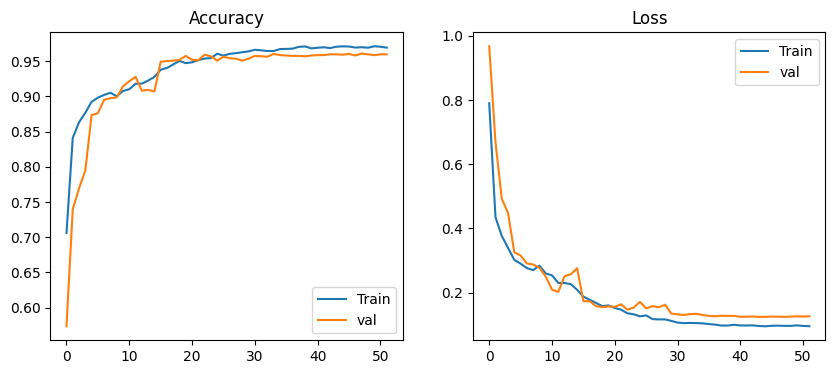

In [ ]:
#Training Curves
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label ='Train')
plt.plot(history.history['val_accuracy'], label='val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label ='Train')
plt.plot(history.history['val_loss'], label='val')
plt.title("Loss")
plt.legend()

plt.show()

56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


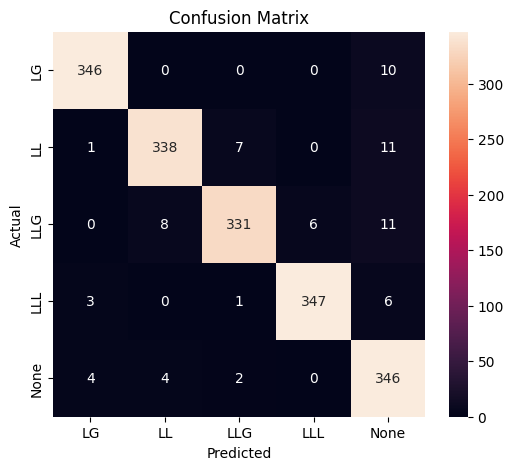

In [ ]:
#Confusion
y_pred = model.predict(X_test)
y_pred_cls = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_true, y_pred_cls)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=["LG","LL","LLG","LLL","None"],
            yticklabels=["LG","LL","LLG","LLL","None"])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion Matrix")
plt.show()


In [ ]:
print(classification_report(
    y_true,
    y_pred_cls,
    target_names=["LG","LL","LLG","LLL","None"]
))

              precision    recall  f1-score   support

          LG       0.98      0.97      0.97       356
          LL       0.97      0.95      0.96       357
         LLG       0.97      0.93      0.95       356
         LLL       0.98      0.97      0.98       357
        None       0.90      0.97      0.94       356

    accuracy                           0.96      1782
   macro avg       0.96      0.96      0.96      1782
weighted avg       0.96      0.96      0.96      1782



In [ ]:
model.save("/content/drive/My Drive/Datasets/1D_CNN_model.keras")